In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression


In [3]:
s = r"D:\MLtrial\archive\FuelConsumptionCo2.csv"
print(f"from URL {s} \n")
df = pd.read_csv(s)
# df.tail()
df.describe()

from URL D:\MLtrial\archive\FuelConsumptionCo2.csv 



,MODELYEAR,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
count,1067.0,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000
mean,2014.0,3.346298,5.794752,13.296532,9.474602,11.580881,26.441425,256.228679
std,0.0,1.415895,1.797447,4.101253,2.794510,3.485595,7.468702,63.372304
min,2014.0,1.000000,3.000000,4.600000,4.900000,4.700000,11.000000,108.000000
25%,2014.0,2.000000,4.000000,10.250000,7.500000,9.000000,21.000000,207.000000
50%,2014.0,3.400000,6.000000,12.600000,8.800000,10.900000,26.000000,251.000000
75%,2014.0,4.300000,8.000000,15.550000,10.850000,13.350000,31.000000,294.000000
max,2014.0,8.400000,12.000000,30.200000,20.500000,25.800000,60.000000,488.000000


In [4]:
X = df.iloc[:, [4]]
y = df.iloc[: , 12]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

In [6]:
reg = LinearRegression( n_jobs=650)
reg.fit(X_train, y_train)


,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",650
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[39.54]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['ENGINESIZE']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,124.6
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [8]:
reg.score(X_test, y_test) # R^2 score it is not an accuracy \
reg.predict(X_test)


array([262.9442894 , 262.9442894 , 338.06998627, 243.17436917,
       334.11600223, 195.72656061, 266.89827344, 369.70185864,
       262.9442894 , 322.25405009, 334.11600223, 187.81859252,
       310.39209795, 310.39209795, 270.85225749, 179.91062443,
       262.9442894 , 262.9442894 , 266.89827344, 342.02397032,
       243.17436917, 243.17436917, 223.40444894, 203.63452871,
       203.63452871, 243.17436917, 207.58851275, 179.91062443,
       223.40444894, 175.95664038, 187.81859252, 274.80624154,
       349.93193841, 231.31241703, 203.63452871, 262.9442894 ,
       243.17436917, 183.86460848, 456.68950766, 334.11600223,
       255.03632131, 349.93193841, 203.63452871, 306.43811391,
       262.9442894 , 266.89827344, 219.45046489, 266.89827344,
       262.9442894 , 187.81859252, 377.60982674, 342.02397032,
       282.71420963, 270.85225749, 262.9442894 , 262.9442894 ,
       369.70185864, 266.89827344, 219.45046489, 203.63452871,
       274.80624154, 243.17436917, 334.11600223, 322.25

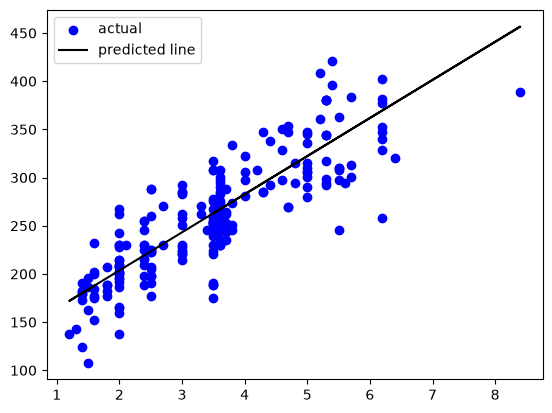

In [9]:
plt.scatter(X_test, y_test, label='actual', color= 'blue')
plt.plot(X_test, reg.predict(X_test), label= 'predicted line', color= 'black')
plt.legend()
plt.show()